# Explainable, Imbalance-Aware Early Prediction of At-Risk Students
### Temporal validation on OULAD with cross-dataset generalization to UCI Student Performance

**Author:** Md. Selim Mia, Department of Artificial Intelligence, Nanjing University of Information Science & Technology (NUIST)

---

This notebook is the complete, reproducible experimental pipeline for the paper. Every table and figure
the paper needs is written to `results/` (tables as CSV + LaTeX, figures as 300-dpi PNG + vector PDF).

**Research questions**

| RQ | Question | Section |
|---|---|---|
| RQ1 | How accurately can at-risk students (Fail / Withdrawn) be identified, and which model family performs best under a realistic *train-on-past, predict-next-semester* protocol? | §6–§8 |
| RQ2 | How early in a course can a reliable warning be issued? | §9 |
| RQ3 | Which information sources (demographics, VLE engagement, assessments) and which imbalance strategies drive performance? | §10 |
| RQ4 | Which factors explain individual predictions (SHAP)? | §11 |
| RQ5 | Is the early-warning model equally reliable across demographic groups? | §12 |
| RQ6 | Do the conclusions generalise to a different education system (secondary school, Portugal)? | §13 |

**Methodological safeguards (the problems fixed relative to the course-project version)**

1. Real, citable datasets: OULAD (Kuzilek et al., *Scientific Data*, 2017) and UCI Student Performance (Cortez & Silva, 2008).
2. **No test-set tuning.** Hyper-parameters and decision thresholds are chosen only from cross-validation on the training cohort.
3. **Temporal hold-out:** train on 2013B, 2013J, 2014B presentations; test on the unseen 2014J presentation.
4. **Group-aware CV:** `StratifiedGroupKFold` on `id_student`, so a student who repeats a module never appears in two folds.
5. **No temporal leakage:** at cutoff day *t* only clicks and submissions recorded before day *t* are used; students who already withdrew before *t* are removed (their outcome is already known).
6. Imbalance-aware metrics (PR-AUC, balanced accuracy, MCC, recall of the at-risk class) with **bootstrap 95% CIs**.
7. Statistical tests: Friedman + Nemenyi on repeated CV, DeLong test on the hold-out ROC-AUCs (Holm-corrected).
8. Strong baselines (XGBoost, LightGBM, CatBoost, MLP) alongside the classical LR / DT / RF / KNN.
9. Nested cross-validation for the small UCI dataset.

## 1. Setup
On Kaggle: **Settings → Internet → On**, and attach the two datasets listed in §2 (or let the notebook download them).

In [1]:
import sys, subprocess, importlib

def _ensure(pip_name, module_name=None):
    try:
        importlib.import_module(module_name or pip_name)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=False)

for _pip, _mod in [("xgboost", None), ("lightgbm", None), ("catboost", None), ("shap", None),
                   ("imbalanced-learn", "imblearn"), ("scikit-posthocs", "scikit_posthocs")]:
    _ensure(_pip, _mod)

In [2]:
import os, io, json, time, zipfile, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
from scipy.stats import loguniform, randint, uniform, norm

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict, cross_val_score)
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, recall_score, precision_score, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import shap
import scikit_posthocs as sp

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"   # also silence warnings inside parallel (joblib) worker processes
pd.set_option("display.width", 200, "display.max_columns", 50)

### Configuration
`RUN_MODE = "full"` reproduces the paper (≈1–2 h on a Kaggle CPU session). `"fast"` is a quick smoke test (≈10 min).

In [3]:
RUN_MODE = "full"          # "full" for the paper, "fast" for a quick check
FAST = RUN_MODE == "fast"

SEED = 42
np.random.seed(SEED)

CUTOFFS = [0, 30, 60, 90, 120, 150]     # days after module start at which a prediction is issued
MAIN_CUTOFF = 60                        # main analysis point (≈ first quarter of a ~240-day course)
TEST_PRESENTATION = "2014J"             # temporal hold-out: the most recent presentation
SCORE_LAG_DAYS = 0                      # days between submission and grade release (sensitivity knob)

CV_FOLDS = 5
N_ITER = 8 if FAST else 30              # random-search iterations per model
CV_REPEATS = 1 if FAST else 3           # repeated CV for the Friedman test
N_BOOT = 200 if FAST else 2000          # bootstrap resamples for 95% CIs
N_ITER_UCI = 4 if FAST else 15
N_TREES = 150 if FAST else 400
SHAP_SAMPLE = 500 if FAST else 2000
N_JOBS = -1

OUT = Path("results")
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

# IEEE-style figures: serif font, 3.5-inch single-column width, vector PDF + 300-dpi PNG.
mpl.rcParams.update({
    "font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "legend.fontsize": 6.5, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "lines.linewidth": 1.4, "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
COL1, COL2 = 3.5, 7.16   # IEEE single / double column widths (inches)

# Validated colour-blind-safe categorical palette, assigned in fixed order; line styles give a second,
# print-safe encoding so curves remain distinguishable in grayscale.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
LINESTYLES = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1)), (0, (5, 2, 1, 2))]
MODEL_ORDER = ["LR", "KNN", "DT", "RF", "XGB", "LightGBM", "CatBoost", "MLP"]
STYLE = {m: dict(color=PALETTE[i], ls=LINESTYLES[i]) for i, m in enumerate(MODEL_ORDER)}

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

def legend_below(fig, ax, ncol=4, y=-0.02):
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)

def shrink_fonts(fig, size=7):
    """SHAP plotting functions hard-code large fonts; bring them back to IEEE size."""
    for ax in fig.axes:
        for item in [ax.title, ax.xaxis.label, ax.yaxis.label] + ax.get_xticklabels() + ax.get_yticklabels():
            item.set_fontsize(size)

def save_table(df, name, index=True, caption=None):
    df.to_csv(TAB / f"{name}.csv", index=index)
    try:
        latex = df.to_latex(index=index, float_format="%.3f", escape=True, caption=caption,
                            label=f"tab:{name}")
        (TAB / f"{name}.tex").write_text(latex)
    except Exception as e:      # to_latex needs jinja2; CSV is always written
        print(f"(LaTeX export skipped for {name}: {e})")

print("Mode:", RUN_MODE, "| outputs ->", OUT.resolve())

Mode: full | outputs -> /kaggle/working/results


## 2. Data acquisition

| Dataset | Kaggle (Add Data → search) | Official source | Citation |
|---|---|---|---|
| OULAD | `anlgrbz/student-demographics-online-education-dataoulad` | https://analyse.kmi.open.ac.uk/open_dataset · UCI id 349 | Kuzilek, Hlosta & Zdrahal, *Sci. Data* 4, 170171 (2017), doi:10.1038/sdata.2017.171 |
| UCI Student Performance | search "student-por.csv" (e.g. `larsen0966/student-performance-data-set`) | UCI id 320, doi:10.24432/C5TG7T | Cortez & Silva, FUBUTEC 2008 |

The loader searches `/kaggle/input`, `./data` and the working directory for the files by name. If they are
not attached it downloads the official UCI archives (Internet must be on).

In [4]:
SEARCH_ROOTS = [Path("/kaggle/input"), Path("data"), Path(".")]
OULAD_FILES = ["courses.csv", "assessments.csv", "vle.csv", "studentInfo.csv",
               "studentRegistration.csv", "studentAssessment.csv", "studentVle.csv"]
OULAD_URL = "https://archive.ics.uci.edu/static/public/349/open+university+learning+analytics+dataset.zip"
UCI_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

def find_file(name):
    target = name.lower()
    for root in SEARCH_ROOTS:
        if not root.exists():
            continue
        for p in root.rglob("*.csv"):
            if p.name.lower() == target and "results" not in p.parts:
                return p
    return None

def _extract_flat(fobj, dest):
    """Extract a (possibly nested) zip into dest, flattening paths (prevents path traversal)."""
    with zipfile.ZipFile(fobj) as z:
        for n in z.namelist():
            if n.endswith("/"):
                continue
            data = z.read(n)
            if n.lower().endswith(".zip"):
                _extract_flat(io.BytesIO(data), dest)
            else:
                (dest / Path(n).name).write_bytes(data)

def download_zip(url, dest):
    dest.mkdir(parents=True, exist_ok=True)
    print("Downloading", url)
    with urllib.request.urlopen(url, timeout=900) as r:
        _extract_flat(io.BytesIO(r.read()), dest)

paths = {f: find_file(f) for f in OULAD_FILES}
if any(v is None for v in paths.values()):
    download_zip(OULAD_URL, Path("data/oulad"))
    paths = {f: find_file(f) for f in OULAD_FILES}
missing = [f for f, p in paths.items() if p is None]
assert not missing, f"OULAD files not found: {missing}"
for f, p in paths.items():
    print(f"{f:26s} -> {p}")

courses.csv                -> data/oulad/courses.csv
assessments.csv            -> data/oulad/assessments.csv
vle.csv                    -> data/oulad/vle.csv
studentInfo.csv            -> data/oulad/studentInfo.csv
studentRegistration.csv    -> data/oulad/studentRegistration.csv
studentAssessment.csv      -> data/oulad/studentAssessment.csv
studentVle.csv             -> data/oulad/studentVle.csv


## 3. Loading OULAD

In [5]:
def read(name, **kw):
    df = pd.read_csv(paths[name], na_values=["?"], **kw)
    df.columns = df.columns.str.strip()
    return df

courses = read("courses.csv")
assessments = read("assessments.csv")
vle = read("vle.csv")
info = read("studentInfo.csv")
reg = read("studentRegistration.csv")
sass = read("studentAssessment.csv")
svle = read("studentVle.csv",
            usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"],
            dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32",
                   "id_site": "int32", "date": "int16", "sum_click": "int32"})

site_type = vle.drop_duplicates("id_site").set_index("id_site")["activity_type"]
svle["activity_type"] = svle["id_site"].map(site_type).astype("category")

KEYS = ["code_module", "code_presentation", "id_student"]
for name, df in [("courses", courses), ("assessments", assessments), ("vle", vle), ("studentInfo", info),
                 ("studentRegistration", reg), ("studentAssessment", sass), ("studentVle", svle)]:
    print(f"{name:20s} {df.shape}")

courses              (22, 3)
assessments          (206, 6)
vle                  (6364, 6)
studentInfo          (32593, 12)
studentRegistration  (32593, 5)
studentAssessment    (173912, 5)
studentVle           (10655280, 7)


## 4. Leakage-free feature engineering at cutoff day *t*

* **Target:** `at_risk = 1` if `final_result ∈ {Fail, Withdrawn}`, else 0 (Pass, Distinction).
* **Cohort at *t*:** students still registered at day *t* (`date_unregistration` missing or ≥ *t*).
* **Demographic / registration features** are known at enrolment.
* **VLE features** use only clicks with `date < t` (pre-course clicks included).
* **Assessment features** use only non-exam assessments submitted before `t − SCORE_LAG_DAYS`.
* `final_result`, `date_unregistration` and `code_presentation` are never used as inputs.

In [6]:
IMD_ORDER = {f"{10*i}-{10*(i+1)}%": i for i in range(10)}
EDU_ORDER = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2,
             "HE Qualification": 3, "Post Graduate Qualification": 4}
AGE_ORDER = {"0-35": 0, "35-55": 1, "55<=": 2}

def base_table():
    df = info.merge(reg, on=KEYS, how="left").merge(courses, on=["code_module", "code_presentation"], how="left")
    df["at_risk"] = df["final_result"].isin(["Fail", "Withdrawn"]).astype(int)
    df["gender_M"] = (df["gender"] == "M").astype(int)
    df["disability_Y"] = (df["disability"] == "Y").astype(int)
    df["imd_ord"] = df["imd_band"].replace({"10-20": "10-20%"}).map(IMD_ORDER)
    df["edu_ord"] = df["highest_education"].map(EDU_ORDER)
    df["age_ord"] = df["age_band"].map(AGE_ORDER)
    df["reg_days_before_start"] = -df["date_registration"]
    return df

BASE = base_table()
DEMO_NUM = ["gender_M", "disability_Y", "imd_ord", "edu_ord", "age_ord", "num_of_prev_attempts",
            "studied_credits", "reg_days_before_start", "module_presentation_length"]
DEMO_CAT = ["code_module", "region"]

TOP_TYPES = svle.groupby("activity_type", observed=True)["sum_click"].sum().nlargest(10).index.astype(str).tolist()
VLE_COLS = (["vle_total_clicks", "vle_log_clicks", "vle_active_days", "vle_distinct_sites",
             "vle_clicks_prestart", "vle_clicks_last14", "vle_days_since_last", "vle_no_activity",
             "vle_week_mean", "vle_week_std", "vle_week_slope", "vle_click_pct_in_cohort",
             "vle_active_pct_in_cohort"] + [f"vle_type_{t}" for t in TOP_TYPES] + ["vle_type_other"])
ASM_COLS = ["asm_n_submitted", "asm_n_due", "asm_n_missed", "asm_submit_rate", "asm_mean_score",
            "asm_min_score", "asm_weighted_score", "asm_n_below40", "asm_n_late", "asm_mean_days_early",
            "asm_n_banked"]

def vle_features(t):
    s = svle[svle["date"] < t]
    g = s.groupby(KEYS, observed=True)
    f = pd.DataFrame({"vle_total_clicks": g["sum_click"].sum(), "vle_active_days": g["date"].nunique(),
                      "vle_distinct_sites": g["id_site"].nunique(), "_last": g["date"].max()})
    f["vle_clicks_prestart"] = s[s["date"] < 0].groupby(KEYS, observed=True)["sum_click"].sum()
    f["vle_clicks_last14"] = s[s["date"] >= t - 14].groupby(KEYS, observed=True)["sum_click"].sum()
    by_type = s.groupby(KEYS + ["activity_type"], observed=True)["sum_click"].sum().unstack(fill_value=0)
    by_type.columns = by_type.columns.astype(str)
    for typ in TOP_TYPES:
        f[f"vle_type_{typ}"] = by_type[typ] if typ in by_type else 0
    other = [c for c in by_type.columns if c not in TOP_TYPES]
    f["vle_type_other"] = by_type[other].sum(axis=1) if other else 0

    # Weekly engagement over weeks 0..W-1 of the course (zero-click weeks included).
    W = int(np.ceil(t / 7))
    if W >= 1:
        post = s[s["date"] >= 0]
        weekly = (post.assign(wk=(post["date"] // 7).astype("int32"))
                  .groupby(KEYS + ["wk"], observed=True)["sum_click"].sum().reset_index())
        c = weekly["sum_click"].astype(float)
        weekly = weekly.assign(c=c, c2=c ** 2, wc=weekly["wk"] * c)
        agg = weekly.groupby(KEYS, observed=True)[["c", "c2", "wc"]].sum()
        mean = agg["c"] / W
        var = (agg["c2"] / W - mean ** 2).clip(lower=0)
        # closed-form OLS slope of weekly clicks on week index 0..W-1 (zero-click weeks included)
        slope = ((agg["wc"] / W - (W - 1) / 2 * mean) / ((W ** 2 - 1) / 12)) if W > 1 else 0 * mean
        f = f.join(pd.DataFrame({"vle_week_mean": mean, "vle_week_std": np.sqrt(var), "vle_week_slope": slope}))
    f = f.reset_index()
    f["vle_days_since_last"] = t - f.pop("_last")
    return f

def asm_features(t):
    a = assessments[(assessments["assessment_type"] != "Exam") & assessments["date"].notna()]
    due = a[a["date"] < t].groupby(["code_module", "code_presentation"]).size().rename("asm_n_due").reset_index()
    sa = sass.merge(a[["id_assessment", "code_module", "code_presentation", "date", "weight"]], on="id_assessment")
    sa = sa[sa["date_submitted"] < t - SCORE_LAG_DAYS].copy()
    sa["late"] = (sa["date_submitted"] > sa["date"]).astype(int)
    sa["days_early"] = sa["date"] - sa["date_submitted"]
    sa["due_before_t"] = (sa["date"] < t).astype(int)
    sa["ws"], sa["w"] = sa["score"] * sa["weight"], sa["weight"].where(sa["score"].notna(), 0)
    g = sa.groupby(KEYS)
    f = pd.DataFrame({"asm_n_submitted": g.size(), "_n_due_sub": g["due_before_t"].sum(),
                      "asm_mean_score": g["score"].mean(), "asm_min_score": g["score"].min(),
                      "_ws": g["ws"].sum(), "_w": g["w"].sum(),
                      "asm_n_below40": g["score"].apply(lambda x: (x < 40).sum()),
                      "asm_n_late": g["late"].sum(), "asm_mean_days_early": g["days_early"].mean(),
                      "asm_n_banked": g["is_banked"].sum()}).reset_index()
    f["asm_weighted_score"] = np.where(f["_w"] > 0, f["_ws"] / f["_w"].replace(0, np.nan), f["asm_mean_score"])
    return f, due

def build_dataset(t):
    df = BASE[BASE["date_unregistration"].isna() | (BASE["date_unregistration"] >= t)].copy()
    df = df.merge(vle_features(t), on=KEYS, how="left")
    af, due = asm_features(t)
    df = df.merge(af, on=KEYS, how="left").merge(due, on=["code_module", "code_presentation"], how="left")
    count_cols = ["vle_total_clicks", "vle_active_days", "vle_distinct_sites", "vle_clicks_prestart",
                  "vle_clicks_last14", "vle_week_mean", "vle_week_std", "vle_week_slope",
                  "vle_type_other"] + [f"vle_type_{x}" for x in TOP_TYPES] + \
                 ["asm_n_submitted", "_n_due_sub", "asm_n_below40", "asm_n_late", "asm_n_banked", "asm_n_due"]
    for c in count_cols:
        if c not in df:
            df[c] = 0.0
        df[c] = df[c].fillna(0).astype(float)
    df["vle_log_clicks"] = np.log1p(df["vle_total_clicks"])
    df["vle_no_activity"] = (df["vle_total_clicks"] == 0).astype(int)
    # vle_days_since_last stays NaN for students with no clicks (median-imputed + missing indicator).
    grp = df.groupby(["code_module", "code_presentation"])
    df["vle_click_pct_in_cohort"] = grp["vle_total_clicks"].rank(pct=True)
    df["vle_active_pct_in_cohort"] = grp["vle_active_days"].rank(pct=True)
    df["asm_n_missed"] = (df["asm_n_due"] - df["_n_due_sub"]).clip(lower=0)
    df["asm_submit_rate"] = np.where(df["asm_n_due"] > 0, df["_n_due_sub"] / df["asm_n_due"].replace(0, np.nan), np.nan)
    for c in VLE_COLS + ASM_COLS:
        if c not in df:
            df[c] = np.nan
    return df.reset_index(drop=True)

FEATURES_NUM = DEMO_NUM + VLE_COLS + ASM_COLS
FEATURE_GROUP = {**{c: "Demographic" for c in DEMO_NUM + DEMO_CAT},
                 **{c: "VLE engagement" for c in VLE_COLS}, **{c: "Assessment" for c in ASM_COLS}}

t0 = time.time()
DATA = {t: build_dataset(t) for t in CUTOFFS}
print(f"Feature tables built in {time.time()-t0:.1f}s")
for t, d in DATA.items():
    print(f"t={t:3d}: n={len(d):6d}  at-risk={d['at_risk'].mean():.3f}  features={len(FEATURES_NUM)+len(DEMO_CAT)}")

Feature tables built in 24.6s
t=  0: n= 29915  at-risk=0.486  features=46
t= 30: n= 27526  at-risk=0.441  features=46
t= 60: n= 26403  at-risk=0.417  features=46
t= 90: n= 25592  at-risk=0.399  features=46
t=120: n= 24781  at-risk=0.379  features=46
t=150: n= 24095  at-risk=0.361  features=46


## 5. Dataset description (Table I, Fig. 1)

,students,modules,pass_,distinction,fail,withdrawn,at_risk,split
code_presentation,,,,,,,,
2013B,4684,3,0.377,0.070,0.265,0.288,0.553,train
2013J,8845,6,0.421,0.085,0.226,0.268,0.494,train
2014B,7804,6,0.330,0.100,0.235,0.335,0.570,train
2014J,11260,7,0.381,0.103,0.176,0.340,0.515,test


,t=0,t=30,t=60,t=90,t=120,t=150
students at risk of prediction,29915.000,27526.000,26403.000,25592.000,24781.000,24095.000
at-risk rate,0.486,0.441,0.417,0.399,0.379,0.361
of which test,10365.000,9210.000,8837.000,8537.000,8261.000,8030.000


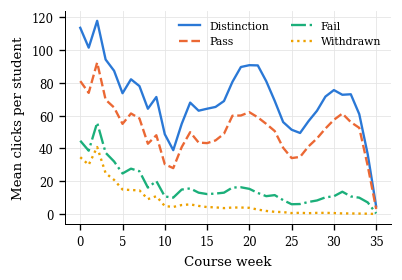

In [7]:
desc = (BASE.groupby("code_presentation")
        .agg(students=("id_student", "size"), modules=("code_module", "nunique"),
             pass_=("final_result", lambda s: (s == "Pass").mean()),
             distinction=("final_result", lambda s: (s == "Distinction").mean()),
             fail=("final_result", lambda s: (s == "Fail").mean()),
             withdrawn=("final_result", lambda s: (s == "Withdrawn").mean()),
             at_risk=("at_risk", "mean")))
desc["split"] = np.where(desc.index == TEST_PRESENTATION, "test", "train")
cohort = pd.DataFrame({f"t={t}": [len(DATA[t]), DATA[t]["at_risk"].mean(),
                                  (DATA[t]["code_presentation"] == TEST_PRESENTATION).sum()]
                       for t in CUTOFFS}, index=["students at risk of prediction", "at-risk rate", "of which test"])
display(desc.round(3)); display(cohort.round(3))
save_table(desc.round(4), "table1_oulad_presentations", caption="OULAD presentations and outcome distribution")
save_table(cohort.round(4), "table1b_cohort_by_cutoff", caption="Prediction cohort at each cutoff")

# Fig. 1: average weekly VLE clicks per student by final outcome.
post = svle[(svle["date"] >= 0) & (svle["date"] < 7 * 36)]
wk = (post.assign(week=(post["date"] // 7).astype("int32"))
      .groupby(KEYS + ["week"], observed=True)["sum_click"].sum().reset_index())
wk["code_module"], wk["code_presentation"] = wk["code_module"].astype(str), wk["code_presentation"].astype(str)
wk = wk.merge(info[KEYS + ["final_result"]], on=KEYS)
n_out = info["final_result"].value_counts()
curve = wk.groupby(["final_result", "week"])["sum_click"].sum().unstack(0).div(n_out)
fig, ax = plt.subplots(figsize=(COL1, 2.3))
for i, outc in enumerate(["Distinction", "Pass", "Fail", "Withdrawn"]):
    if outc in curve:
        ax.plot(curve.index, curve[outc], label=outc, color=PALETTE[i], ls=LINESTYLES[i])
ax.set_xlabel("Course week"); ax.set_ylabel("Mean clicks per student")
ax.legend(frameon=False, ncol=2)
save_fig(fig, "fig1_weekly_clicks_by_outcome")

## 6. Models, search spaces and temporal split (main cutoff)

In [8]:
def split_xy(df, num=FEATURES_NUM, cat=DEMO_CAT):
    test = df["code_presentation"] == TEST_PRESENTATION
    tr, te = df[~test], df[test]
    cols = num + cat
    return (tr[cols], tr["at_risk"].values, tr["id_student"].values,
            te[cols], te["at_risk"].values, te)

def make_preprocessor(num, cat):
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    trans = [("num", num_pipe, num)] + ([("cat", cat_pipe, cat)] if cat else [])
    return ColumnTransformer(trans, verbose_feature_names_out=False)

from sklearn.base import BaseEstimator, ClassifierMixin

class CatBoostSK(ClassifierMixin, BaseEstimator):
    """Thin scikit-learn wrapper around CatBoostClassifier.
    CatBoost's own get_params/set_params are not fully compatible with sklearn.clone in some library
    versions (RuntimeError during cross-validation). The wrapper keeps hyper-parameters as plain attributes
    and builds the CatBoost model only inside fit(), so cloning is always safe."""
    def __init__(self, iterations=400, depth=6, learning_rate=0.1, l2_leaf_reg=3.0,
                 auto_class_weights="Balanced", random_seed=42, thread_count=1):
        self.iterations, self.depth, self.learning_rate = iterations, depth, learning_rate
        self.l2_leaf_reg, self.auto_class_weights = l2_leaf_reg, auto_class_weights
        self.random_seed, self.thread_count = random_seed, thread_count

    def fit(self, X, y):
        self.model_ = CatBoostClassifier(
            iterations=int(self.iterations), depth=int(self.depth), learning_rate=float(self.learning_rate),
            l2_leaf_reg=float(self.l2_leaf_reg), auto_class_weights=self.auto_class_weights,
            random_seed=int(self.random_seed), thread_count=int(self.thread_count),
            verbose=0, allow_writing_files=False)
        self.model_.fit(np.asarray(X, dtype=float), np.asarray(y))
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X, dtype=float))

    def predict(self, X):
        return self.classes_[(self.predict_proba(X)[:, 1] >= 0.5).astype(int)]

def model_zoo(pos_weight):
    return {
        "LR": (LogisticRegression(max_iter=5000, class_weight="balanced"),
               {"clf__C": loguniform(1e-3, 1e2)}),
        "KNN": (KNeighborsClassifier(),
                {"clf__n_neighbors": randint(5, 151), "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]}),
        "DT": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
               {"clf__max_depth": randint(2, 16), "clf__min_samples_leaf": randint(5, 200),
                "clf__criterion": ["gini", "entropy"]}),
        "RF": (RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced_subsample", n_jobs=1,
                                      random_state=SEED),
               {"clf__max_depth": [None, 6, 10, 16, 24], "clf__min_samples_leaf": randint(1, 30),
                "clf__max_features": ["sqrt", 0.3, 0.5]}),
        "XGB": (XGBClassifier(n_estimators=N_TREES, tree_method="hist", eval_metric="logloss",
                              scale_pos_weight=pos_weight, n_jobs=1, random_state=SEED, verbosity=0),
                {"clf__learning_rate": loguniform(0.01, 0.3), "clf__max_depth": randint(3, 9),
                 "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
                 "clf__min_child_weight": randint(1, 10), "clf__reg_lambda": loguniform(1e-2, 10)}),
        "LightGBM": (LGBMClassifier(n_estimators=N_TREES, class_weight="balanced", n_jobs=1, verbose=-1,
                                    random_state=SEED, subsample_freq=1),
                     {"clf__learning_rate": loguniform(0.01, 0.3), "clf__num_leaves": randint(15, 128),
                      "clf__min_child_samples": randint(10, 100), "clf__subsample": uniform(0.6, 0.4),
                      "clf__colsample_bytree": uniform(0.5, 0.5), "clf__reg_lambda": loguniform(1e-2, 10)}),
        "CatBoost": (CatBoostSK(iterations=N_TREES, auto_class_weights="Balanced", random_seed=SEED),
                     {"clf__depth": randint(4, 9), "clf__learning_rate": loguniform(0.02, 0.3),
                      "clf__l2_leaf_reg": loguniform(1, 10)}),
        "MLP": (MLPClassifier(max_iter=400, early_stopping=True, random_state=SEED),
                {"clf__hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64)],
                 "clf__alpha": loguniform(1e-5, 1e-1), "clf__learning_rate_init": loguniform(1e-4, 1e-2)}),
    }

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])

def metrics(y, p, thr):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Bal. Acc.": balanced_accuracy_score(y, yhat), "F1 (at-risk)": f1_score(y, yhat, zero_division=0),
            "Macro-F1": f1_score(y, yhat, average="macro", zero_division=0), "MCC": matthews_corrcoef(y, yhat),
            "Recall": tp / max(tp + fn, 1), "Precision": tp / max(tp + fp, 1),
            "Specificity": tn / max(tn + fp, 1), "Brier": brier_score_loss(y, p)}

def bootstrap_ci(y, p, thr, n=N_BOOT, keys=("ROC-AUC", "PR-AUC", "Bal. Acc.", "F1 (at-risk)", "MCC", "Recall")):
    rng = np.random.default_rng(SEED)
    out = {k: [] for k in keys}
    idx = np.arange(len(y))
    for _ in range(n):
        b = rng.choice(idx, len(idx), replace=True)
        if y[b].min() == y[b].max():
            continue
        m = metrics(y[b], p[b], thr)
        for k in keys:
            out[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

D = DATA[MAIN_CUTOFF]
Xtr, ytr, gtr, Xte, yte, te_df = split_xy(D)
POS_W = float((ytr == 0).sum() / (ytr == 1).sum())
CV = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
print(f"Train: {len(ytr)} enrolments ({ytr.mean():.3f} at-risk) | Test ({TEST_PRESENTATION}): {len(yte)} ({yte.mean():.3f} at-risk)")
print(f"Students appearing in both train and test (module repeaters / multi-module): "
      f"{len(set(gtr) & set(te_df['id_student']))}")

Train: 17566 enrolments (0.435 at-risk) | Test (2014J): 8837 (0.382 at-risk)
Students appearing in both train and test (module repeaters / multi-module): 1149


### 6.1 Smoke test (≈1 min)
Fits, clones and cross-validates every model once on a small subsample, so that any library-version
incompatibility shows up in a minute instead of after an hour of tuning.

In [9]:
_rng = np.random.default_rng(SEED)
_idx = _rng.choice(len(ytr), min(1500, len(ytr)), replace=False)
for _n, (_clf, _dist) in model_zoo(POS_W).items():
    _p = Pipeline([("pre", make_preprocessor(FEATURES_NUM, DEMO_CAT)), ("clf", _clf)])
    _s = RandomizedSearchCV(_p, _dist, n_iter=1, scoring="average_precision",
                            cv=StratifiedGroupKFold(2, shuffle=True, random_state=SEED),
                            random_state=SEED, error_score="raise")
    _s.fit(Xtr.iloc[_idx], ytr[_idx], groups=gtr[_idx])
    _bp = {k: (v.item() if hasattr(v, "item") else v) for k, v in _s.best_params_.items()}
    cross_val_predict(clone(_p).set_params(**_bp), Xtr.iloc[_idx], ytr[_idx], groups=gtr[_idx],
                      cv=StratifiedGroupKFold(2, shuffle=True, random_state=SEED), method="predict_proba")
    clone(_s.best_estimator_)
    print(f"{_n:9s} OK")
print("All models passed the smoke test.")

LR        OK
KNN       OK
DT        OK
RF        OK
XGB       OK
LightGBM  OK
CatBoost  OK
MLP       OK
All models passed the smoke test.


## 7. Hyper-parameter tuning (training cohort only) and threshold selection
Random search optimises **PR-AUC** under group-aware 5-fold CV. The decision threshold is then chosen to
maximise F1 of the at-risk class on **out-of-fold** training predictions, never on the test set.

In [10]:
ZOO = model_zoo(POS_W)
TUNED, THR, OOF, CV_BEST, SEARCH_TIME, TEMPLATE, BEST_PARAMS = {}, {}, {}, {}, {}, {}, {}

def fresh(name):
    """Unfitted copy of a tuned pipeline. Cloning the unfitted template (exactly what RandomizedSearchCV
    does internally) avoids CatBoost's failure when sklearn.clone is applied to an already-fitted model."""
    return clone(TEMPLATE[name]).set_params(**BEST_PARAMS[name])

for name, (clf, dist) in ZOO.items():
    t1 = time.time()
    pipe = Pipeline([("pre", make_preprocessor(FEATURES_NUM, DEMO_CAT)), ("clf", clf)])
    search = RandomizedSearchCV(pipe, dist, n_iter=N_ITER, scoring="average_precision", cv=CV,
                                n_jobs=N_JOBS, random_state=SEED, error_score=np.nan, refit=True)
    search.fit(Xtr, ytr, groups=gtr)
    TUNED[name] = search.best_estimator_
    TEMPLATE[name] = pipe
    BEST_PARAMS[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
    CV_BEST[name] = search.best_score_
    OOF[name] = cross_val_predict(fresh(name), Xtr, ytr, groups=gtr, cv=CV,
                                  method="predict_proba", n_jobs=N_JOBS)[:, 1]
    THR[name] = best_f1_threshold(ytr, OOF[name])
    SEARCH_TIME[name] = time.time() - t1
    print(f"{name:9s} CV PR-AUC={search.best_score_:.4f}  thr={THR[name]:.3f}  ({SEARCH_TIME[name]:.0f}s)")

params = {n: {k.replace("clf__", ""): (v if isinstance(v, (int, float, str, type(None))) else str(v))
              for k, v in TUNED[n].get_params().items() if k.startswith("clf__") and k in ZOO[n][1]}
          for n in TUNED}
(TAB / "tuned_hyperparameters.json").write_text(json.dumps(params, indent=2, default=str))
pd.DataFrame({"search space": {n: ", ".join(k.replace("clf__", "") for k in ZOO[n][1]) for n in ZOO},
              "selected": {n: json.dumps(params[n], default=str) for n in ZOO}})

LR        CV PR-AUC=0.8262  thr=0.426  (25s)
KNN       CV PR-AUC=0.8147  thr=0.316  (129s)
DT        CV PR-AUC=0.7962  thr=0.413  (31s)
RF        CV PR-AUC=0.8274  thr=0.403  (1643s)
XGB       CV PR-AUC=0.8336  thr=0.440  (167s)
LightGBM  CV PR-AUC=0.8335  thr=0.425  (238s)
CatBoost  CV PR-AUC=0.8331  thr=0.416  (450s)
MLP       CV PR-AUC=0.8304  thr=0.329  (134s)


,search space,selected
LR,C,"{""C"": 0.0745934328572655}"
KNN,"n_neighbors, weights, p","{""n_neighbors"": 63, ""p"": 1, ""weights"": ""distan..."
DT,"max_depth, min_samples_leaf, criterion","{""criterion"": ""entropy"", ""max_depth"": 13, ""min..."
RF,"max_depth, min_samples_leaf, max_features","{""max_depth"": 16, ""max_features"": 0.3, ""min_sa..."
XGB,"learning_rate, max_depth, subsample, colsample...","{""colsample_bytree"": 0.5078182033705969, ""lear..."
LightGBM,"learning_rate, num_leaves, min_child_samples, ...","{""colsample_bytree"": 0.7699205456508366, ""lear..."
CatBoost,"depth, learning_rate, l2_leaf_reg","{""depth"": 7, ""l2_leaf_reg"": 2.7551959649510764..."
MLP,"hidden_layer_sizes, alpha, learning_rate_init","{""alpha"": 0.07556810141274425, ""hidden_layer_s..."


## 8. Hold-out evaluation on the unseen 2014J presentation (RQ1)

In [11]:
PTE = {n: TUNED[n].predict_proba(Xte)[:, 1] for n in TUNED}
rows, ci_rows = [], []
for n in MODEL_ORDER:
    m = metrics(yte, PTE[n], THR[n]); m["Model"] = n; rows.append(m)
    ci = bootstrap_ci(yte, PTE[n], THR[n])
    ci_rows.append({"Model": n, **{k: f"{m[k]:.3f} [{lo:.3f}, {hi:.3f}]" for k, (lo, hi) in ci.items()}})
RES = pd.DataFrame(rows).set_index("Model")
RES_CI = pd.DataFrame(ci_rows).set_index("Model")
display(RES.round(3)); display(RES_CI)
save_table(RES.round(4), "table2_holdout_results",
           caption=f"Hold-out performance on {TEST_PRESENTATION} at day {MAIN_CUTOFF}")
save_table(RES_CI, "table2b_holdout_results_ci", caption="Hold-out performance with bootstrap 95% CIs")

BEST = RES["PR-AUC"].idxmax()
print("Best model by hold-out PR-AUC:", BEST)

,ROC-AUC,PR-AUC,Bal. Acc.,F1 (at-risk),Macro-F1,MCC,Recall,Precision,Specificity,Brier
Model,,,,,,,,,,
LR,0.807,0.752,0.726,0.668,0.720,0.444,0.709,0.631,0.743,0.172
KNN,0.794,0.729,0.718,0.667,0.702,0.424,0.770,0.588,0.666,0.177
DT,0.785,0.724,0.707,0.652,0.694,0.402,0.734,0.586,0.679,0.185
RF,0.809,0.760,0.725,0.673,0.710,0.438,0.768,0.599,0.682,0.172
XGB,0.812,0.758,0.730,0.676,0.721,0.450,0.742,0.621,0.719,0.174
LightGBM,0.813,0.761,0.731,0.678,0.720,0.451,0.753,0.616,0.709,0.173
CatBoost,0.810,0.757,0.727,0.675,0.713,0.442,0.765,0.604,0.689,0.175
MLP,0.811,0.757,0.730,0.675,0.721,0.449,0.740,0.621,0.721,0.168


,ROC-AUC,PR-AUC,Bal. Acc.,F1 (at-risk),MCC,Recall
Model,,,,,,
LR,"0.807 [0.798, 0.816]","0.752 [0.739, 0.766]","0.726 [0.716, 0.736]","0.668 [0.655, 0.681]","0.444 [0.424, 0.464]","0.709 [0.693, 0.725]"
KNN,"0.794 [0.785, 0.803]","0.729 [0.716, 0.743]","0.718 [0.710, 0.728]","0.667 [0.655, 0.679]","0.424 [0.407, 0.443]","0.770 [0.756, 0.784]"
DT,"0.785 [0.775, 0.795]","0.724 [0.710, 0.739]","0.707 [0.697, 0.717]","0.652 [0.640, 0.664]","0.402 [0.383, 0.422]","0.734 [0.720, 0.749]"
RF,"0.809 [0.800, 0.818]","0.760 [0.747, 0.773]","0.725 [0.716, 0.735]","0.673 [0.662, 0.685]","0.438 [0.420, 0.456]","0.768 [0.754, 0.782]"
XGB,"0.812 [0.803, 0.821]","0.758 [0.746, 0.772]","0.730 [0.721, 0.740]","0.676 [0.664, 0.688]","0.450 [0.431, 0.468]","0.742 [0.727, 0.757]"
LightGBM,"0.813 [0.804, 0.822]","0.761 [0.749, 0.774]","0.731 [0.722, 0.741]","0.678 [0.666, 0.690]","0.451 [0.432, 0.469]","0.753 [0.738, 0.768]"
CatBoost,"0.810 [0.801, 0.819]","0.757 [0.745, 0.770]","0.727 [0.718, 0.737]","0.675 [0.663, 0.687]","0.442 [0.424, 0.461]","0.765 [0.751, 0.780]"
MLP,"0.811 [0.802, 0.820]","0.757 [0.744, 0.771]","0.730 [0.721, 0.740]","0.675 [0.663, 0.688]","0.449 [0.431, 0.469]","0.740 [0.725, 0.755]"


Best model by hold-out PR-AUC: LightGBM


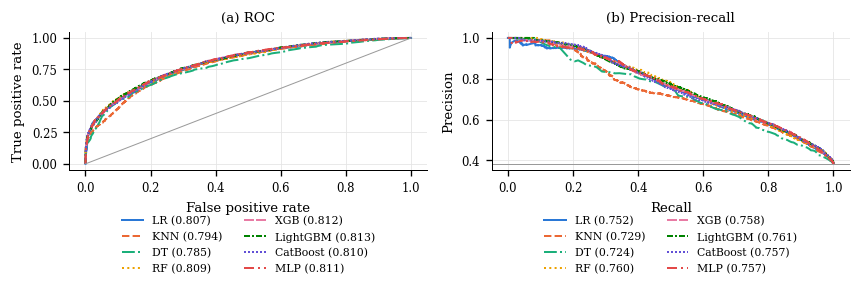

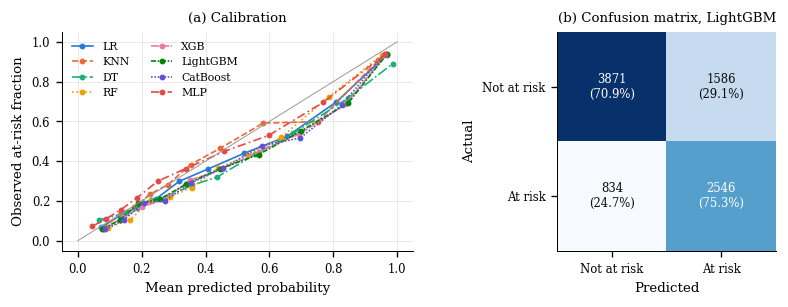

In [14]:
# Fig. 2: ROC and precision-recall curves.
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.7))
for n in MODEL_ORDER:
    fpr, tpr, _ = roc_curve(yte, PTE[n])
    pr, rc, _ = precision_recall_curve(yte, PTE[n])
    axes[0].plot(fpr, tpr, lw=1.2, label=f"{n} ({RES.loc[n,'ROC-AUC']:.3f})", **STYLE[n])
    axes[1].plot(rc, pr, lw=1.2, label=f"{n} ({RES.loc[n,'PR-AUC']:.3f})", **STYLE[n])
axes[0].plot([0, 1], [0, 1], color="#9a9a9a", lw=0.6)
axes[1].axhline(yte.mean(), color="#9a9a9a", lw=0.6)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="(a) ROC")
axes[1].set(xlabel="Recall", ylabel="Precision", title="(b) Precision-recall")
for a in axes:
    a.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.26))   # label = model (AUC)
fig.tight_layout(); save_fig(fig, "fig2_roc_pr_curves")

# Fig. 3: calibration (reliability) and confusion matrix of the best model.
fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.6))
for n in MODEL_ORDER:
    fp_, mp_ = calibration_curve(yte, PTE[n], n_bins=10, strategy="quantile")
    axes[0].plot(mp_, fp_, marker="o", ms=2.5, lw=1, label=n, **STYLE[n])
axes[0].plot([0, 1], [0, 1], color="#9a9a9a", lw=0.6)
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed at-risk fraction", title="(a) Calibration")
axes[0].legend(frameon=False, ncol=2, loc="upper left")
cm = confusion_matrix(yte, (PTE[BEST] >= THR[BEST]).astype(int))
axes[1].imshow(cm, cmap="Blues"); axes[1].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v}\n({v/cm[i].sum():.1%})", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "#0b0b0b", fontsize=7)
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Not at risk", "At risk"],
            yticklabels=["Not at risk", "At risk"], xlabel="Predicted", ylabel="Actual",
            title=f"(b) Confusion matrix, {BEST}")
fig.tight_layout(); save_fig(fig, "fig3_calibration_confusion")

### 8.1 Statistical significance
* **Friedman + Nemenyi** on PR-AUC over repeated group-aware CV folds of the training cohort (Demšar, 2006).
* **DeLong test** comparing the best model's hold-out ROC-AUC with every other model, Holm-corrected.

Friedman chi2=91.78, p=5.34e-17  (15 folds x 8 models)


,mean CV PR-AUC,std,avg rank
XGB,0.8332,0.0108,1.8000
CatBoost,0.8328,0.0110,2.3333
LightGBM,0.8324,0.0107,2.6667
MLP,0.8311,0.0104,3.4000
RF,0.8269,0.0111,5.2667
LR,0.8259,0.0109,5.5333
KNN,0.8149,0.0115,7.0000
DT,0.7949,0.0122,8.0000


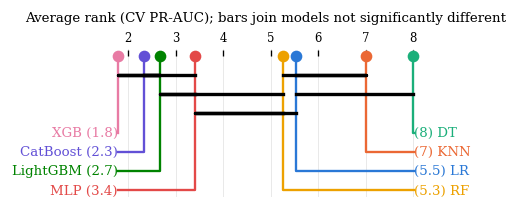

,ΔAUC (best − model),p,p (Holm)
LightGBM vs LR,0.0063,0.0027,0.0107
LightGBM vs KNN,0.0195,0.0000,0.0000
LightGBM vs DT,0.0287,0.0000,0.0000
LightGBM vs RF,0.0042,0.0015,0.0076
LightGBM vs XGB,0.0017,0.0706,0.1412
LightGBM vs CatBoost,0.0028,0.0114,0.0341
LightGBM vs MLP,0.0024,0.1849,0.1849


In [15]:
cv_scores = {n: [] for n in MODEL_ORDER}
for r in range(CV_REPEATS):
    cv_r = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + r)
    for n in MODEL_ORDER:
        cv_scores[n] += list(cross_val_score(fresh(n), Xtr, ytr, groups=gtr, cv=cv_r,
                                             scoring="average_precision", n_jobs=N_JOBS))
CVS = pd.DataFrame(cv_scores)
fried = stats.friedmanchisquare(*[CVS[c] for c in CVS])
print(f"Friedman chi2={fried.statistic:.2f}, p={fried.pvalue:.2e}  ({len(CVS)} folds x {CVS.shape[1]} models)")
nemenyi = sp.posthoc_nemenyi_friedman(CVS.values)
nemenyi.index = nemenyi.columns = CVS.columns
avg_rank = CVS.rank(axis=1, ascending=False).mean().sort_values()
display(pd.DataFrame({"mean CV PR-AUC": CVS.mean(), "std": CVS.std(), "avg rank": avg_rank}).sort_values("avg rank").round(4))
save_table(nemenyi.round(4), "table3_nemenyi_pvalues", caption="Nemenyi post-hoc p-values (CV PR-AUC)")
try:
    fig, ax = plt.subplots(figsize=(COL1, 1.6))
    sp.critical_difference_diagram(avg_rank, nemenyi, ax=ax,
                                   color_palette={m: STYLE[m]["color"] for m in MODEL_ORDER})
    ax.set_title("Average rank (CV PR-AUC); bars join models not significantly different")
    save_fig(fig, "fig4_critical_difference")
except Exception as e:
    print("Critical-difference diagram skipped:", e)

def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(N); out[J] = T
    return out

def delong_test(y, p1, p2):
    """Fast DeLong (Sun & Xu, 2014) test for two correlated ROC-AUCs."""
    y = np.asarray(y).astype(int)
    order = np.argsort(-y, kind="mergesort"); m = int(y.sum()); n = len(y) - m
    P = np.vstack([p1, p2])[:, order]
    tx = np.array([_midrank(r[:m]) for r in P]); ty = np.array([_midrank(r[m:]) for r in P])
    tz = np.array([_midrank(r) for r in P])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1.0) / 2.0 / n
    v01 = (tz[:, :m] - tx) / n; v10 = 1.0 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    l = np.array([1, -1]); z = (aucs[0] - aucs[1]) / np.sqrt(l @ cov @ l)
    return aucs[0] - aucs[1], 2 * norm.sf(abs(z))

def holm(pvals):
    p = np.asarray(pvals); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(run, 1.0)
    return adj

others = [n for n in MODEL_ORDER if n != BEST]
dl = [delong_test(yte, PTE[BEST], PTE[n]) for n in others]
DELONG = pd.DataFrame({"ΔAUC (best − model)": [d for d, _ in dl], "p": [p for _, p in dl],
                       "p (Holm)": holm([p for _, p in dl])}, index=[f"{BEST} vs {n}" for n in others])
display(DELONG.round(4))
save_table(DELONG.round(5), "table4_delong", caption="DeLong tests on hold-out ROC-AUC")

## 9. How early can we predict? (RQ2)
Each model is re-trained at every cutoff with the hyper-parameters selected at the main cutoff, so the
curve isolates the effect of information availability. Bands are bootstrap 95% CIs.

t=  0 done
t= 30 done
t= 60 done
t= 90 done
t=120 done
t=150 done


cutoff,0,30,60,90,120,150
Model,,,,,,
LR,0.722,0.735,0.807,0.833,0.869,0.897
KNN,0.711,0.736,0.794,0.822,0.855,0.884
DT,0.681,0.713,0.785,0.804,0.852,0.879
RF,0.717,0.745,0.809,0.830,0.871,0.900
XGB,0.727,0.753,0.812,0.831,0.875,0.902
LightGBM,0.724,0.747,0.813,0.834,0.877,0.904
CatBoost,0.727,0.754,0.810,0.837,0.872,0.902
MLP,0.725,0.737,0.811,0.838,0.869,0.899


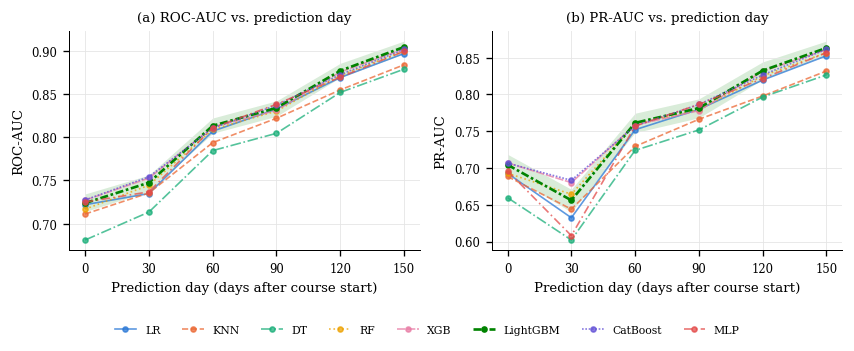

In [18]:
early_rows = []
for t in CUTOFFS:
    Xa, ya, ga, Xb, yb, _ = split_xy(DATA[t])
    for n in MODEL_ORDER:
        est = fresh(n)
        if "scale_pos_weight" in est.named_steps["clf"].get_params():
            est.set_params(clf__scale_pos_weight=float((ya == 0).sum() / (ya == 1).sum()))
        est.fit(Xa, ya)
        p = est.predict_proba(Xb)[:, 1]
        row = {"cutoff": t, "Model": n, "ROC-AUC": roc_auc_score(yb, p), "PR-AUC": average_precision_score(yb, p),
               "n_test": len(yb), "test at-risk rate": yb.mean()}
        if n == BEST:
            ci = bootstrap_ci(yb, p, 0.5, n=max(N_BOOT // 4, 100), keys=("ROC-AUC", "PR-AUC"))
            row.update({"ROC lo": ci["ROC-AUC"][0], "ROC hi": ci["ROC-AUC"][1],
                        "PR lo": ci["PR-AUC"][0], "PR hi": ci["PR-AUC"][1]})
        early_rows.append(row)
    print(f"t={t:3d} done")
EARLY = pd.DataFrame(early_rows)
early_tab = EARLY.pivot(index="Model", columns="cutoff", values="ROC-AUC").loc[MODEL_ORDER]
display(early_tab.round(3))
save_table(early_tab.round(4), "table5_early_prediction_rocauc", caption="Hold-out ROC-AUC by prediction day")
save_table(EARLY.pivot(index="Model", columns="cutoff", values="PR-AUC").loc[MODEL_ORDER].round(4),
           "table5b_early_prediction_prauc", caption="Hold-out PR-AUC by prediction day")

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.6))
for k, (metric, lo, hi) in enumerate([("ROC-AUC", "ROC lo", "ROC hi"), ("PR-AUC", "PR lo", "PR hi")]):
    ax = axes[k]
    for n in MODEL_ORDER:
        e = EARLY[EARLY["Model"] == n]
        ax.plot(e["cutoff"], e[metric], marker="o", ms=3, lw=1.6 if n == BEST else 1,
                label=n, alpha=1 if n == BEST else 0.75, **STYLE[n])
        if n == BEST:
            ax.fill_between(e["cutoff"], e[lo], e[hi], color=STYLE[n]["color"], alpha=0.15, lw=0)
    ax.set(xlabel="Prediction day (days after course start)", ylabel=metric, xticks=CUTOFFS,
           title=f"({'ab'[k]}) {metric} vs. prediction day")
fig.tight_layout(); legend_below(fig, axes[0], ncol=8); save_fig(fig, "fig5_early_prediction")

## 10. Ablation studies (RQ3)
### 10.1 Information sources

In [19]:
best_clf = fresh(BEST).named_steps["clf"]      # unfitted, tuned hyper-parameters
GROUPS = {"Demographic only": (DEMO_NUM, DEMO_CAT), "VLE only": (VLE_COLS, []), "Assessment only": (ASM_COLS, []),
          "Demographic + VLE": (DEMO_NUM + VLE_COLS, DEMO_CAT),
          "Demographic + Assessment": (DEMO_NUM + ASM_COLS, DEMO_CAT),
          "VLE + Assessment": (VLE_COLS + ASM_COLS, []), "All (proposed)": (FEATURES_NUM, DEMO_CAT)}
abl = []
for gname, (num, cat) in GROUPS.items():
    Xa, ya, ga, Xb, yb, _ = split_xy(D, num, cat)
    pipe = Pipeline([("pre", make_preprocessor(num, cat)), ("clf", clone(best_clf))]).fit(Xa, ya)
    p = pipe.predict_proba(Xb)[:, 1]
    ci = bootstrap_ci(yb, p, 0.5, n=max(N_BOOT // 4, 100), keys=("ROC-AUC", "PR-AUC"))
    abl.append({"Feature set": gname, "n features": len(num) + len(cat), "ROC-AUC": roc_auc_score(yb, p),
                "ROC-AUC 95% CI": f"[{ci['ROC-AUC'][0]:.3f}, {ci['ROC-AUC'][1]:.3f}]",
                "PR-AUC": average_precision_score(yb, p),
                "PR-AUC 95% CI": f"[{ci['PR-AUC'][0]:.3f}, {ci['PR-AUC'][1]:.3f}]"})
ABL_FEAT = pd.DataFrame(abl).set_index("Feature set")
display(ABL_FEAT.round(3))
save_table(ABL_FEAT.round(4), "table6_ablation_feature_groups",
           caption=f"Feature-group ablation ({BEST}, day {MAIN_CUTOFF})")

,n features,ROC-AUC,ROC-AUC 95% CI,PR-AUC,PR-AUC 95% CI
Feature set,,,,,
Demographic only,11,0.639,"[0.626, 0.651]",0.516,"[0.498, 0.532]"
VLE only,24,0.759,"[0.749, 0.769]",0.691,"[0.675, 0.707]"
Assessment only,11,0.784,"[0.774, 0.794]",0.719,"[0.706, 0.734]"
Demographic + VLE,35,0.775,"[0.765, 0.785]",0.707,"[0.692, 0.722]"
Demographic + Assessment,22,0.797,"[0.788, 0.807]",0.737,"[0.724, 0.751]"
VLE + Assessment,35,0.806,"[0.797, 0.815]",0.753,"[0.740, 0.766]"
All (proposed),46,0.813,"[0.805, 0.822]",0.761,"[0.748, 0.774]"


### 10.2 Class-imbalance strategies
Threshold-dependent metrics are reported at the default 0.5 threshold except for the last row, which shows
that tuning the threshold on out-of-fold predictions is an alternative to re-weighting.

In [21]:
def unweighted(clf):
    c = clone(clf); prm = c.get_params()
    for k, v in [("class_weight", None), ("scale_pos_weight", 1.0), ("auto_class_weights", None)]:
        if k in prm:
            c.set_params(**{k: v})
    return c

pre = lambda: make_preprocessor(FEATURES_NUM, DEMO_CAT)
STRATS = {
    "None": lambda: Pipeline([("pre", pre()), ("clf", unweighted(best_clf))]),
    "Cost-sensitive weighting": lambda: Pipeline([("pre", pre()), ("clf", clone(best_clf))]),
    "SMOTE": lambda: ImbPipeline([("pre", pre()), ("smote", SMOTE(random_state=SEED)), ("clf", unweighted(best_clf))]),
    "Random under-sampling": lambda: ImbPipeline([("pre", pre()), ("rus", RandomUnderSampler(random_state=SEED)),
                                                  ("clf", unweighted(best_clf))]),
}
imb = []
for sname, make in STRATS.items():
    pipe = make().fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]
    imb.append({"Strategy": sname, "Threshold": 0.5, **metrics(yte, p, 0.5)})
    if sname == "None":
        oof = cross_val_predict(make(), Xtr, ytr, groups=gtr, cv=CV, method="predict_proba", n_jobs=N_JOBS)[:, 1]
        thr_none = best_f1_threshold(ytr, oof)
        imb.append({"Strategy": "None + OOF-tuned threshold", "Threshold": thr_none, **metrics(yte, p, thr_none)})
ABL_IMB = pd.DataFrame(imb).set_index("Strategy")
display(ABL_IMB.round(3))
save_table(ABL_IMB.round(4), "table7_ablation_imbalance", caption=f"Imbalance-handling ablation ({BEST})")

,Threshold,ROC-AUC,PR-AUC,Bal. Acc.,F1 (at-risk),Macro-F1,MCC,Recall,Precision,Specificity,Brier
Strategy,,,,,,,,,,,
None,0.500,0.814,0.762,0.730,0.664,0.733,0.467,0.642,0.687,0.819,0.168
None + OOF-tuned threshold,0.378,0.814,0.762,0.732,0.678,0.722,0.453,0.747,0.621,0.718,0.168
Cost-sensitive weighting,0.500,0.813,0.761,0.731,0.671,0.729,0.458,0.688,0.654,0.774,0.173
SMOTE,0.500,0.810,0.757,0.727,0.661,0.728,0.455,0.655,0.668,0.798,0.172
Random under-sampling,0.500,0.810,0.756,0.730,0.671,0.725,0.453,0.702,0.642,0.758,0.177


## 11. Explainability with SHAP (RQ4)
TreeSHAP on the best tree-based model, computed on a random sample of the hold-out cohort.

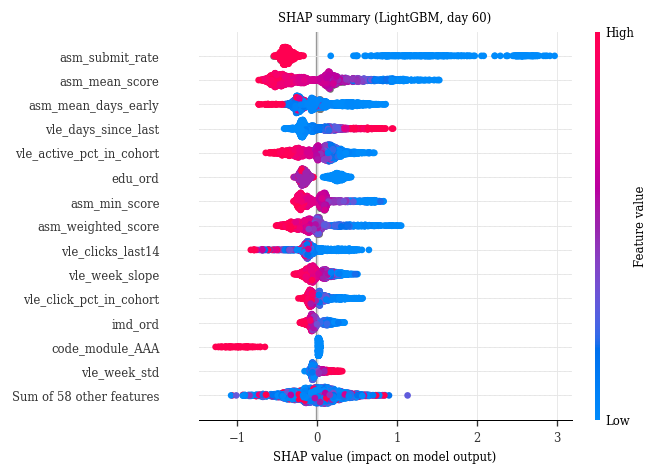

,base,group,mean|SHAP|
10,asm_submit_rate,Assessment,0.5837
2,asm_mean_score,Assessment,0.4105
1,asm_mean_days_early,Assessment,0.2242
27,vle_days_since_last,VLE engagement,0.2006
23,vle_active_pct_in_cohort,VLE engagement,0.1995
14,edu_ord,Demographic,0.1982
3,asm_min_score,Assessment,0.1958
11,asm_weighted_score,Assessment,0.1839
25,vle_clicks_last14,VLE engagement,0.1579
12,code_module,Demographic,0.1517


group
Assessment        0.466
VLE engagement    0.340
Demographic       0.194
Name: share of total |SHAP|, dtype: float64

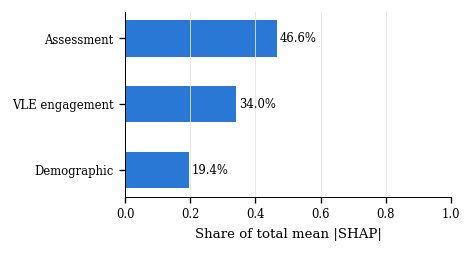

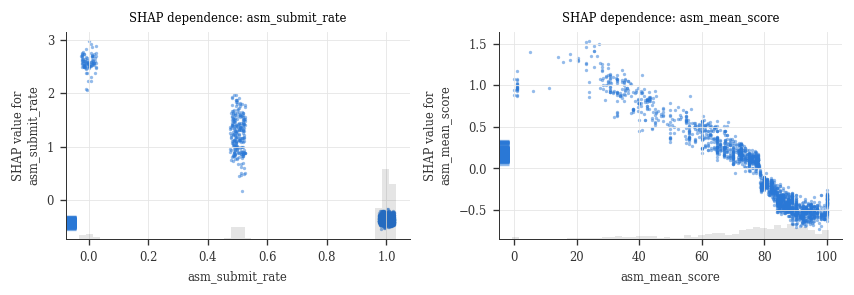

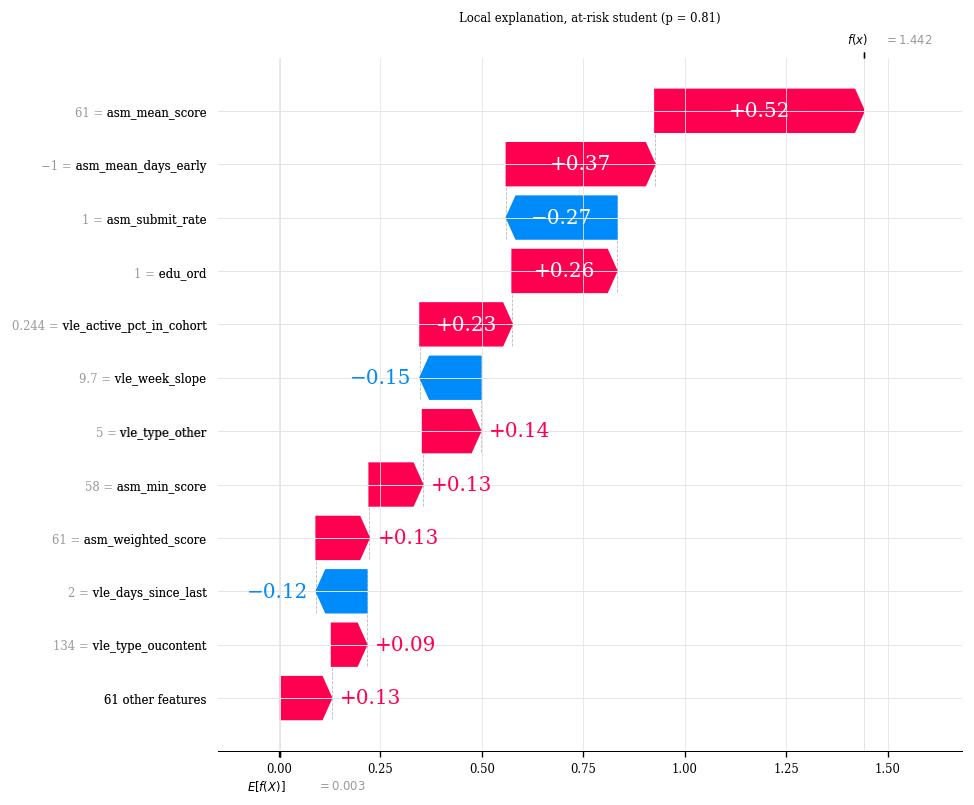

In [22]:
TREE_MODELS = ["LightGBM", "XGB", "CatBoost", "RF", "DT"]
EXPL = BEST if BEST in TREE_MODELS else RES.loc[TREE_MODELS, "PR-AUC"].idxmax()
pipe = TUNED[EXPL]
names = list(pipe.named_steps["pre"].get_feature_names_out())
rng = np.random.default_rng(SEED)
sidx = rng.choice(len(Xte), min(SHAP_SAMPLE, len(Xte)), replace=False)
Xs = pd.DataFrame(pipe.named_steps["pre"].transform(Xte.iloc[sidx]), columns=names)
# Show raw (un-standardised) values on the colour axis for readability.
num_raw = Xte.iloc[sidx][FEATURES_NUM].reset_index(drop=True)
Xs_disp = Xs.copy()
for c in FEATURES_NUM:
    if c in Xs_disp:
        Xs_disp[c] = num_raw[c].values
_clf = pipe.named_steps["clf"]
explainer = shap.TreeExplainer(getattr(_clf, "model_", _clf))   # unwrap CatBoostSK
sv = explainer(Xs)
if sv.values.ndim == 3:            # (n, features, classes) for sklearn forests/trees
    sv = sv[:, :, 1]
sv.data = Xs_disp.values
sv.feature_names = names

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, plot_size=(COL2 * 0.7, 4.2))
plt.title(f"SHAP summary ({EXPL}, day {MAIN_CUTOFF})"); shrink_fonts(plt.gcf())
save_fig(plt.gcf(), "fig6_shap_beeswarm")

def base_name(f):
    f = f.replace("missingindicator_", "")
    for c in DEMO_CAT:
        if f.startswith(c + "_"):
            return c
    return f
imp = pd.DataFrame({"feature": names, "mean|SHAP|": np.abs(sv.values).mean(0)})
imp["base"] = imp["feature"].map(base_name)
imp["group"] = imp["base"].map(FEATURE_GROUP).fillna("Demographic")
feat_imp = imp.groupby(["base", "group"])["mean|SHAP|"].sum().reset_index().sort_values("mean|SHAP|", ascending=False)
grp_imp = imp.groupby("group")["mean|SHAP|"].sum().sort_values(ascending=False)
grp_imp = (grp_imp / grp_imp.sum()).rename("share of total |SHAP|")
display(feat_imp.head(20).round(4)); display(grp_imp.round(3))
save_table(feat_imp.round(5).reset_index(drop=True), "table8_shap_feature_importance", index=False,
           caption="Mean absolute SHAP value per feature")
save_table(grp_imp.round(4).to_frame(), "table8b_shap_group_importance",
           caption="Share of attribution per information source")

fig, ax = plt.subplots(figsize=(COL1, 2.0))
ax.barh(grp_imp.index[::-1], grp_imp.values[::-1], color=PALETTE[0], height=0.55)
for y_, v in enumerate(grp_imp.values[::-1]):
    ax.text(v + 0.01, y_, f"{v:.1%}", va="center", fontsize=7)
ax.set(xlabel="Share of total mean |SHAP|", xlim=(0, 1)); ax.grid(axis="y", visible=False)
save_fig(fig, "fig7_shap_group_share")

top2 = feat_imp[feat_imp["base"].isin(names)]["base"].head(2).tolist()
fig, axes = plt.subplots(1, len(top2), figsize=(COL2, 2.5))
for ax, f in zip(np.atleast_1d(axes), top2):
    shap.plots.scatter(sv[:, f], ax=ax, show=False, color=PALETTE[0], dot_size=4, alpha=0.5)
    ax.set_title(f"SHAP dependence: {f}")
shrink_fonts(fig); fig.tight_layout(); save_fig(fig, "fig8_shap_dependence")

# Local explanation: a correctly flagged at-risk student (true positive) for the case study.
p_s = pipe.predict_proba(Xte.iloc[sidx])[:, 1]
tp_idx = np.where((yte[sidx] == 1) & (p_s >= THR[EXPL]))[0]
if len(tp_idx):
    i = tp_idx[np.argsort(p_s[tp_idx])[len(tp_idx) // 2]]
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(f"Local explanation, at-risk student (p = {p_s[i]:.2f})"); shrink_fonts(plt.gcf())
    save_fig(plt.gcf(), "fig9_shap_waterfall_case")

## 12. Fairness audit of the early-warning model (RQ5)
Group-wise true-positive rate (did we catch the at-risk students?), false-positive rate, precision and
selection rate at the deployed threshold. Disparities: equal-opportunity gap (max − min TPR),
equalised-odds gap (max of TPR and FPR gaps), and disparate-impact ratio (min / max selection rate).

n  Base rate  Selection rate    TPR    FPR  Precision  ROC-AUC
Attribute         Group                                                                                         
Gender            F                            3735      0.362           0.511  0.762  0.370      0.539    0.776
                  M                            5102      0.398           0.436  0.748  0.229      0.683    0.841
Disability        N                            8031      0.371           0.455  0.746  0.283      0.609    0.812
                  Y                             806      0.499           0.597  0.806  0.389      0.674    0.809
Age band          0-35                         6041      0.396           0.500  0.786  0.313      0.623    0.823
                  35-55                        2715      0.354           0.399  0.675  0.248      0.599    0.793
                  55<=                           81      0.309           0.309  0.600  0.179      0.600    0.809
IMD quintile      Q1 (most deprived)           1652      0.459           0.593  0.826  0.395      0.639    0.803
                  Q2                           1879      0.415           0.505  0.787  0.305      0.647    0.819
                  Q3                           1763      0.379           0.474  0.756  0.301      0.605    0.814
                  Q4                           1691      0.358           0.420  0.714  0.257      0.608    0.813
                  Q5 (least deprived)          1493      0.315           0.386  0.667  0.257      0.544    0.796
                  Unknown                       359      0.273           0.226  0.561  0.100      0.679    0.806
Highest education A Level or Equivalent        3929      0.349           0.411  0.703  0.255      0.597    0.808
                  HE Qualification             1507      0.314           0.344  0.668  0.196      0.609    0.816
                  Lower Than A Level           3228      0.456           0.596  0.830  0.400      0.635    0.807
                  No Formal quals                63      0.508           0.698  0.875  0.516      0.636    0.814
                  Post Graduate Qualification   110      0.273           0.255  0.500  0.162      0.536    0.747

,Equal-opportunity gap,Equalised-odds gap,Disparate-impact ratio,ROC-AUC range
Attribute,,,,
Gender,0.014,0.140,0.852,0.064
Disability,0.060,0.106,0.762,0.003
Age band,0.186,0.186,0.617,0.030
IMD quintile,0.265,0.295,0.381,0.023
Highest education,0.375,0.375,0.364,0.069


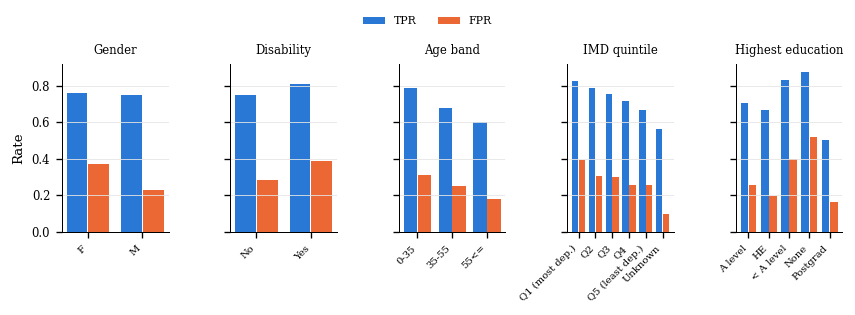

In [23]:
fair_df = te_df.reset_index(drop=True).copy()
fair_df["p"], fair_df["yhat"] = PTE[BEST], (PTE[BEST] >= THR[BEST]).astype(int)
fair_df["IMD quintile"] = (fair_df["imd_ord"] // 2).map({0: "Q1 (most deprived)", 1: "Q2", 2: "Q3", 3: "Q4",
                                                       4: "Q5 (least deprived)"}).fillna("Unknown")
ATTRS = {"Gender": "gender", "Disability": "disability", "Age band": "age_band",
         "IMD quintile": "IMD quintile", "Highest education": "highest_education"}
frows, summ = [], []
for label, col in ATTRS.items():
    sub = []
    for g, d in fair_df.groupby(col):
        if len(d) < 30:
            continue
        tn, fp, fn, tp = confusion_matrix(d["at_risk"], d["yhat"], labels=[0, 1]).ravel()
        r = {"Attribute": label, "Group": g, "n": len(d), "Base rate": d["at_risk"].mean(),
             "Selection rate": d["yhat"].mean(), "TPR": tp / max(tp + fn, 1), "FPR": fp / max(fp + tn, 1),
             "Precision": tp / max(tp + fp, 1),
             "ROC-AUC": roc_auc_score(d["at_risk"], d["p"]) if d["at_risk"].nunique() == 2 else np.nan}
        frows.append(r); sub.append(r)
    s = pd.DataFrame(sub)
    summ.append({"Attribute": label, "Equal-opportunity gap": s["TPR"].max() - s["TPR"].min(),
                 "Equalised-odds gap": max(s["TPR"].max() - s["TPR"].min(), s["FPR"].max() - s["FPR"].min()),
                 "Disparate-impact ratio": s["Selection rate"].min() / max(s["Selection rate"].max(), 1e-9),
                 "ROC-AUC range": s["ROC-AUC"].max() - s["ROC-AUC"].min()})
FAIR = pd.DataFrame(frows).set_index(["Attribute", "Group"])
FAIR_SUM = pd.DataFrame(summ).set_index("Attribute")
display(FAIR.round(3)); display(FAIR_SUM.round(3))
save_table(FAIR.round(4), "table9_fairness_by_group", caption=f"Group-wise performance of {BEST}")
save_table(FAIR_SUM.round(4), "table9b_fairness_summary", caption="Fairness disparity summary")

SHORT = {"Q1 (most deprived)": "Q1 (most dep.)", "Q5 (least deprived)": "Q5 (least dep.)",
         "A Level or Equivalent": "A level", "HE Qualification": "HE", "Lower Than A Level": "< A level",
         "No Formal quals": "None", "Post Graduate Qualification": "Postgrad", "N": "No", "Y": "Yes"}
fig, axes = plt.subplots(1, len(ATTRS), figsize=(COL2, 2.4), sharey=True)
for ax, label in zip(axes, ATTRS):
    d = FAIR.loc[label]
    x = np.arange(len(d)); w = 0.38
    ax.bar(x - w / 2 - 0.01, d["TPR"], w, color=PALETTE[0], label="TPR")
    ax.bar(x + w / 2 + 0.01, d["FPR"], w, color=PALETTE[1], label="FPR")
    ax.set_xticks(x); ax.set_xticklabels([SHORT.get(str(g), str(g)) for g in d.index], rotation=45, ha="right", fontsize=6)
    ax.set_title(label, fontsize=7); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Rate")
fig.tight_layout(); legend_below(fig, axes[0], ncol=2, y=1.08); save_fig(fig, "fig10_fairness")

## 13. Cross-dataset generalisation: UCI Student Performance (RQ6)
Target: **fail = final grade G3 < 10** (Portuguese 0–20 scale). Two realistic early-warning scenarios:
* **S1, enrolment time:** demographic, social and school features only (G1, G2, G3 removed).
* **S2, after the first period:** S1 + G1 (G2, G3 removed).

With only 649 (Portuguese) / 395 (Mathematics) students, a fixed split is unreliable, so we use
**nested cross-validation**: outer repeated stratified 5-fold for evaluation, inner 3-fold random search for
tuning, and an inner out-of-fold threshold, so no outer-test information is ever used for selection.

{'por': PosixPath('data/uci/student-por.csv'), 'mat': PosixPath('data/uci/student-mat.csv')}
Portuguese: n=649, fail rate=0.154
  S1 enrolment: 836s
  S2 after period 1: 817s
Mathematics: n=395, fail rate=0.329
  S1 enrolment: 779s
  S2 after period 1: 765s


ROC-AUC         PR-AUC      Bal. Acc.   F1 (at-risk)            MCC         Recall
Dataset     Scenario          Model                                                                                             
Mathematics S1 enrolment      CatBoost  0.678 ± 0.049  0.550 ± 0.060  0.602 ± 0.039  0.518 ± 0.038  0.206 ± 0.073  0.721 ± 0.154
                              DT        0.654 ± 0.048  0.495 ± 0.058  0.595 ± 0.051  0.482 ± 0.092  0.195 ± 0.101  0.603 ± 0.194
                              KNN       0.652 ± 0.057  0.537 ± 0.083  0.576 ± 0.038  0.515 ± 0.030  0.162 ± 0.077  0.813 ± 0.095
                              LR        0.686 ± 0.047  0.549 ± 0.059  0.625 ± 0.045  0.535 ± 0.053  0.243 ± 0.091  0.715 ± 0.132
                              LightGBM  0.671 ± 0.078  0.521 ± 0.090  0.586 ± 0.049  0.496 ± 0.066  0.183 ± 0.107  0.700 ± 0.211
                              MLP       0.614 ± 0.057  0.490 ± 0.064  0.568 ± 0.053  0.483 ± 0.054  0.148 ± 0.089  0.690 ± 0.227
                              RF        0.701 ± 0.043  0.569 ± 0.056  0.614 ± 0.043  0.521 ± 0.038  0.236 ± 0.087  0.682 ± 0.185
                              XGB       0.678 ± 0.079  0.525 ± 0.074  0.621 ± 0.068  0.541 ± 0.065  0.236 ± 0.132  0.774 ± 0.117
            S2 after period 1 CatBoost  0.923 ± 0.020  0.851 ± 0.049  0.837 ± 0.033  0.765 ± 0.035  0.645 ± 0.056  0.877 ± 0.090
                              DT        0.915 ± 0.019  0.817 ± 0.038  0.821 ± 0.035  0.752 ± 0.038  0.627 ± 0.058  0.810 ± 0.097
                              KNN       0.874 ± 0.034  0.761 ± 0.066  0.777 ± 0.032  0.694 ± 0.035  0.532 ± 0.058  0.815 ± 0.105
                              LR        0.923 ± 0.019  0.852 ± 0.045  0.822 ± 0.035  0.750 ± 0.040  0.621 ± 0.065  0.849 ± 0.091
                              LightGBM  0.919 ± 0.023  0.846 ± 0.063  0.825 ± 0.039  0.754 ± 0.045  0.629 ± 0.064  0.833 ± 0.106
                              MLP       0.894 ± 0.042  0.807 ± 0.085  0.802 ± 0.050  0.730 ± 0.062  0.589 ± 0.102  0.787 ± 0.075
                              RF        0.924 ± 0.019  0.852 ± 0.047  0.831 ± 0.046  0.757 ± 0.048  0.637 ± 0.073  0.867 ± 0.129
                              XGB       0.926 ± 0.019  0.859 ± 0.053  0.831 ± 0.036  0.759 ± 0.040  0.634 ± 0.066  0.856 ± 0.080
Portuguese  S1 enrolment      CatBoost  0.820 ± 0.031  0.503 ± 0.056  0.729 ± 0.046  0.494 ± 0.054  0.396 ± 0.068  0.620 ± 0.119
                              DT        0.795 ± 0.039  0.431 ± 0.069  0.720 ± 0.067  0.493 ± 0.092  0.401 ± 0.098  0.567 ± 0.160
                              KNN       0.781 ± 0.045  0.444 ± 0.085  0.699 ± 0.045  0.446 ± 0.047  0.334 ± 0.061  0.583 ± 0.113
                              LR        0.810 ± 0.037  0.451 ± 0.051  0.726 ± 0.036  0.477 ± 0.044  0.373 ± 0.058  0.647 ± 0.079
                              LightGBM  0.799 ± 0.028  0.462 ± 0.065  0.713 ± 0.050  0.457 ± 0.060  0.356 ± 0.064  0.620 ± 0.157
                              MLP       0.748 ± 0.091  0.410 ± 0.098  0.657 ± 0.093  0.391 ± 0.133  0.298 ± 0.135  0.467 ± 0.222
                              RF        0.835 ± 0.033  0.509 ± 0.064  0.750 ± 0.057  0.507 ± 0.049  0.420 ± 0.064  0.677 ± 0.162
                              XGB       0.808 ± 0.032  0.469 ± 0.059  0.728 ± 0.051  0.488 ± 0.053  0.392 ± 0.065  0.623 ± 0.149
            S2 after period 1 CatBoost  0.938 ± 0.013  0.703 ± 0.084  0.837 ± 0.032  0.693 ± 0.043  0.638 ± 0.053  0.750 ± 0.076
                              DT        0.917 ± 0.025  0.672 ± 0.059  0.700 ± 0.076  0.532 ± 0.129  0.511 ± 0.120  0.423 ± 0.157
                              KNN       0.874 ± 0.031  0.564 ± 0.075  0.769 ± 0.038  0.548 ± 0.050  0.463 ± 0.063  0.690 ± 0.093
                              LR        0.929 ± 0.017  0.698 ± 0.091  0.828 ± 0.033  0.653 ± 0.053  0.589 ± 0.063  0.760 ± 0.069
                              LightGBM  0.930 ± 0.019  0.689 ± 0.083  0.839 ± 0.035  0.695 ± 0.043  0.642 ± 0.053  0.757 ± 0.092
                              MLP       0.805 ±

Mathematics / S1 enrolment: Friedman p=3.938e-03; best=RF (PR-AUC 0.569)
Mathematics / S2 after period 1: Friedman p=1.933e-08; best=XGB (PR-AUC 0.859)
Portuguese / S1 enrolment: Friedman p=3.181e-06; best=RF (PR-AUC 0.509)
Portuguese / S2 after period 1: Friedman p=4.060e-10; best=RF (PR-AUC 0.726)


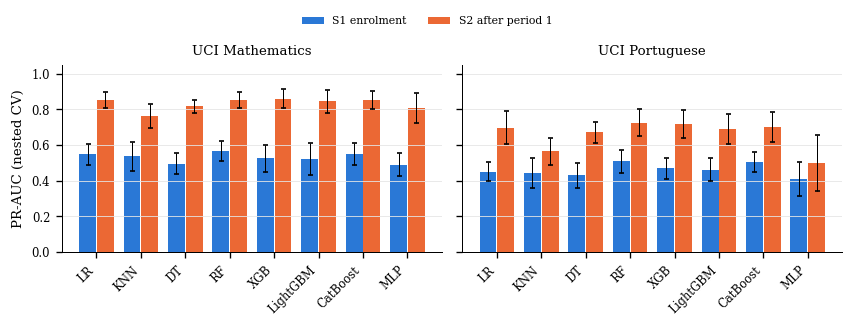

In [24]:
uci_paths = {k: find_file(f"student-{k}.csv") for k in ("por", "mat")}
if uci_paths["por"] is None:
    download_zip(UCI_URL, Path("data/uci"))
    uci_paths = {k: find_file(f"student-{k}.csv") for k in ("por", "mat")}
print(uci_paths)

def load_uci(p):
    df = pd.read_csv(p, sep=";")
    if df.shape[1] == 1:
        df = pd.read_csv(p)
    df.columns = df.columns.str.strip()
    df["fail"] = (df["G3"] < 10).astype(int)
    return df

def nested_cv(df, drop, label):
    X = df.drop(columns=drop + ["fail"]); y = df["fail"].values
    cat = X.select_dtypes(exclude="number").columns.tolist(); num = [c for c in X if c not in cat]
    outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=CV_REPEATS, random_state=SEED)
    rows = []
    for fold, (a, b) in enumerate(outer.split(X, y)):
        zoo = model_zoo(float((y[a] == 0).sum() / max((y[a] == 1).sum(), 1)))
        for n in MODEL_ORDER:
            clf, dist = zoo[n]
            if n == "KNN":
                dist = {**dist, "clf__n_neighbors": randint(3, 40)}
            pipe = Pipeline([("pre", make_preprocessor(num, cat)), ("clf", clf)])
            inner = StratifiedKFold(3, shuffle=True, random_state=SEED + fold)
            s = RandomizedSearchCV(pipe, dist, n_iter=N_ITER_UCI, scoring="average_precision", cv=inner,
                                   n_jobs=N_JOBS, random_state=SEED, error_score=np.nan).fit(X.iloc[a], y[a])
            oof = cross_val_predict(clone(s.estimator).set_params(**s.best_params_), X.iloc[a], y[a], cv=inner, method="predict_proba",
                                    n_jobs=N_JOBS)[:, 1]
            thr = best_f1_threshold(y[a], oof)
            p = s.best_estimator_.predict_proba(X.iloc[b])[:, 1]
            rows.append({"Dataset": label, "Fold": fold, "Model": n, **metrics(y[b], p, thr)})
    return pd.DataFrame(rows)

uci_res = []
for key, p in uci_paths.items():
    if p is None:
        continue
    df_u = load_uci(p)
    lab = {"por": "Portuguese", "mat": "Mathematics"}[key]
    print(f"{lab}: n={len(df_u)}, fail rate={df_u['fail'].mean():.3f}")
    for scen, drop in [("S1 enrolment", ["G1", "G2", "G3"]), ("S2 after period 1", ["G2", "G3"])]:
        t1 = time.time()
        r = nested_cv(df_u, drop, lab); r["Scenario"] = scen; uci_res.append(r)
        print(f"  {scen}: {time.time()-t1:.0f}s")
UCI = pd.concat(uci_res, ignore_index=True)
KEYM = ["ROC-AUC", "PR-AUC", "Bal. Acc.", "F1 (at-risk)", "MCC", "Recall"]
UCI_SUM = UCI.groupby(["Dataset", "Scenario", "Model"])[KEYM].agg(["mean", "std"])
UCI_FMT = UCI.groupby(["Dataset", "Scenario", "Model"])[KEYM].agg(
    lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
display(UCI_FMT)
save_table(UCI_FMT, "table10_uci_nested_cv", caption="Nested-CV results on UCI Student Performance (mean ± std)")
for (ds, sc), d in UCI.groupby(["Dataset", "Scenario"]):
    piv = d.pivot(index="Fold", columns="Model", values="PR-AUC")[MODEL_ORDER]
    f = stats.friedmanchisquare(*[piv[c] for c in piv])
    best_u = piv.mean().idxmax()
    print(f"{ds} / {sc}: Friedman p={f.pvalue:.3e}; best={best_u} (PR-AUC {piv[best_u].mean():.3f})")

fig, axes = plt.subplots(1, UCI["Dataset"].nunique(), figsize=(COL2, 2.5), sharey=True, squeeze=False)
for ax, (ds, d) in zip(axes[0], UCI.groupby("Dataset")):
    x = np.arange(len(MODEL_ORDER)); w = 0.38
    for k, sc in enumerate(["S1 enrolment", "S2 after period 1"]):
        m = d[d["Scenario"] == sc].groupby("Model")["PR-AUC"].agg(["mean", "std"]).loc[MODEL_ORDER]
        ax.bar(x + (k - 0.5) * (w + 0.02), m["mean"], w, yerr=m["std"], capsize=1.5,
               error_kw={"lw": 0.6}, color=PALETTE[k], label=sc)
    ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=45, ha="right")
    ax.set_title(f"UCI {ds}"); ax.grid(axis="x", visible=False)
axes[0][0].set_ylabel("PR-AUC (nested CV)"); axes[0][0].set_ylim(0, 1.05)
fig.tight_layout(); legend_below(fig, axes[0][0], ncol=2, y=1.08); save_fig(fig, "fig11_uci_generalisation")

## 14. Summary, reproducibility record and export

In [27]:
import sklearn, xgboost, lightgbm, catboost
summary = {
    "run_mode": RUN_MODE, "seed": SEED, "main_cutoff_day": MAIN_CUTOFF, "test_presentation": TEST_PRESENTATION,
    "n_train": int(len(ytr)), "n_test": int(len(yte)), "train_at_risk_rate": float(ytr.mean()),
    "best_model": BEST, "best_holdout": RES.loc[BEST].round(4).to_dict(),
    "friedman_p": float(fried.pvalue), "explained_model": EXPL,
    "shap_group_share": grp_imp.round(4).to_dict(),
    "earliest_day_rocauc_ge_0.80": next((int(t) for t in CUTOFFS
                                         if early_tab.loc[BEST, t] >= 0.80), None),
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "lightgbm": lightgbm.__version__, "catboost": catboost.__version__, "shap": shap.__version__},
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

import shutil
shutil.make_archive("results", "zip", OUT)
print("\nAll tables and figures saved; download results.zip from the Output panel.")

{
  "run_mode": "full",
  "seed": 42,
  "main_cutoff_day": 60,
  "test_presentation": "2014J",
  "n_train": 17566,
  "n_test": 8837,
  "train_at_risk_rate": 0.43481726061710124,
  "best_model": "LightGBM",
  "best_holdout": {
    "ROC-AUC": 0.8132,
    "PR-AUC": 0.7613,
    "Bal. Acc.": 0.7313,
    "F1 (at-risk)": 0.6778,
    "Macro-F1": 0.7199,
    "MCC": 0.4506,
    "Recall": 0.7533,
    "Precision": 0.6162,
    "Specificity": 0.7094,
    "Brier": 0.1731
  },
  "friedman_p": 5.3355628623205596e-17,
  "explained_model": "LightGBM",
  "shap_group_share": {
    "Assessment": 0.4655,
    "VLE engagement": 0.34,
    "Demographic": 0.1945
  },
  "earliest_day_rocauc_ge_0.80": 60,
  "versions": {
    "python": "3.13.15",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "catboost": "1.2.10",
    "shap": "0.52.0"
  }
}

All tables and figures saved; download results.zip from the Output panel.
